# Analiza cantitativă a piețelor de energie — Cursul 3: Volatilitatea prețurilor energiei
Prof. dr. Daniel Traian Pele — Academia de Studii Economice din București; Academia Română, Institutul de Prognoză Economică

Acest notebook Jupyter reproduce modelele, cifrele și graficele din cursul 3 pe datele reale din `../data/clean` (vezi `../data/SOURCES.md`). Numerele secțiunilor (§) corespund indicațiilor *Exercițiu practic* de pe diapozitive.

**Convenții.** Prețul zilnic de bază PZU din România = media tuturor intervalelor zilei de livrare (ora Europei Centrale, CET); perioada 1 ianuarie 2019 – ultima lună completă. Variațiile zilnice se calculează pe calendarul complet, în procente (logaritmic) și în EUR/MWh. Brent: se elimină prima zi de tranzacționare a fiecărei luni (schimbarea contractului). Toate modelele de volatilitate se estimează pe șocurile rămase după ecuația mediei (constantă, 7 decalaje autoregresive, ziua săptămînii).

## §1 Datele, variațiile zilnice și calendarul săptămînal

In [ ]:
# Google Colab: copiem repo-ul cursului, ca datele și rezultatele salvate să fie găsite
import os, subprocess, sys
if 'google.colab' in sys.modules and not os.getcwd().startswith('/content/EMQA'):
    if not os.path.isdir('/content/EMQA'):
        subprocess.run(['git', 'clone', '-q', '--depth', '1', 'https://github.com/danpele/EMQA.git', '/content/EMQA'], check=True)
    os.chdir('/content/EMQA/notebooks')

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, statsmodels.api as sm, warnings
from scipy import stats
from arch import arch_model
from joblib import Parallel, delayed
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.tsa.stattools import acf
from statsmodels.tsa.regime_switching.markov_regression import MarkovRegression
warnings.filterwarnings('ignore')
DATA = '../data/clean/'
TZ = 'Europe/Brussels'

PD = pd.read_csv(DATA + 'power_da_prices_daily_cet.csv', parse_dates=['date_cet']).set_index('date_cet')
FU = pd.read_csv(DATA + 'fuels_daily.csv', parse_dates=['date']).set_index('date')
EUA = pd.read_csv(DATA + 'eua_daily.csv', parse_dates=['date']).set_index('date')['eua_etc_co2l_eur_per_unit']
EQ = pd.read_csv(DATA + 'ro_energy_equities_daily.csv', parse_dates=['date']).set_index('date')
GEN = pd.read_csv(DATA + 'generation_ro_mw_daily_cet.csv', parse_dates=['date_cet']).set_index('date_cet')
raw_last = PD['RO'].dropna().index.max()
END = pd.Timestamp(((raw_last + pd.Timedelta(days=1)).to_period('M').to_timestamp() - pd.Timedelta(days=1)).date())
START = pd.Timestamp('2019-01-01')
CAL = pd.date_range(START, END, freq='D')
PR = {z: PD[z].reindex(CAL) for z in ['RO', 'HU', 'DE_LU']}
print('cut-off (last complete month):', END.date(), '| days:', len(CAL), '| missing RO days:', PR['RO'].isna().sum())

cut-off (last complete month): 2026-10-31 | days: 2861 | missing RO days: 0


days with base price <= 0: {'RO': 0, 'HU': 2, 'DE_LU': 20}
largest |log change| in DE-LU: 458% on 2025-01-02
mean change by weekday, %: {0: 38.3, 1: 4.4, 2: 0.6, 3: -1.0, 4: -4.4, 5: -18.2, 6: -19.2}
mean equation R2: 0.499 (%), 0.411 (EUR/MWh); std 28.3% -> 20.0%


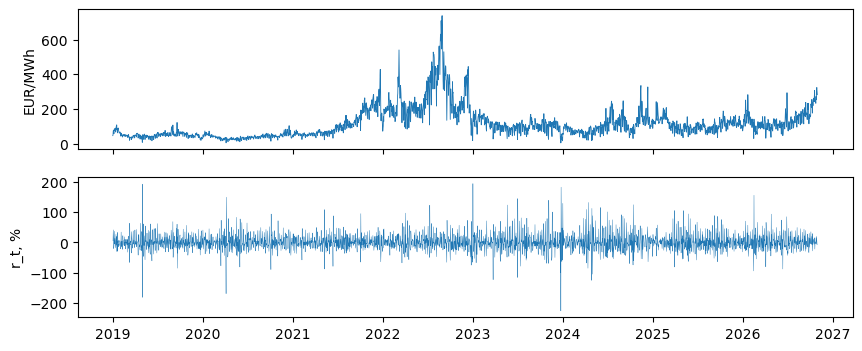

In [2]:
def pct_change(p):
    """100 * log change on the full calendar; missing if either price is <= 0 or missing (no multi-day jumps)."""
    lp = np.log(p.where(p > 0))
    return 100 * lp.diff()


def mean_design(y, lags=7):
    X = pd.DataFrame({f"L{k}": y.shift(k) for k in range(1, lags + 1)}, index=y.index)
    for j in range(1, 7):
        X[f"D{j}"] = (y.index.dayofweek == j).astype(float)
    X.insert(0, "const", 1.0)
    return X


def mean_fit(y, lags=7):
    """OLS mean equation on the full calendar; returns (residual series, fitted model)."""
    X = mean_design(y, lags)
    df = pd.concat([y.rename("y"), X], axis=1).dropna()
    m = sm.OLS(df["y"], df.drop(columns="y")).fit()
    return m.resid, m


R_PCT = {z: pct_change(PR[z]) for z in PR}
R_EUR = {z: PR[z].diff() for z in PR}
print('days with base price <= 0:', {z: int((PR[z] <= 0).sum()) for z in PR})
rde = R_PCT['DE_LU'].dropna(); print('largest |log change| in DE-LU: %.0f%% on %s' % (rde.abs().max(), rde.abs().idxmax().date()))
rr = R_PCT['RO'].dropna()
print('mean change by weekday, %:', rr.groupby(rr.index.dayofweek).mean().round(1).to_dict())
E_PCT, M_PCT = mean_fit(R_PCT['RO']); E_EUR, M_EUR = mean_fit(R_EUR['RO'])
print('mean equation R2: %.3f (%%), %.3f (EUR/MWh); std %.1f%% -> %.1f%%' % (M_PCT.rsquared, M_EUR.rsquared, rr.loc[E_PCT.index].std(), E_PCT.std()))
fig, ax = plt.subplots(2, 1, figsize=(10, 4), sharex=True)
ax[0].plot(PR['RO'], lw=0.6); ax[0].set_ylabel('EUR/MWh'); ax[1].plot(rr, lw=0.3); ax[1].set_ylabel('r_t, %'); plt.show()

## §2 Faptele stilizate: gruparea volatilității, cozi groase, două unități de măsură, volatilitatea pe piețe

Ljung-Box Q(10): shocks 13.8, squared shocks 120.0 (critical 18.31)
ARCH-LM(10): 93.7, p = 9.6e-16
excess kurtosis 20.0, skewness -1.69, |z|>4: 15 (normal: 0.18)


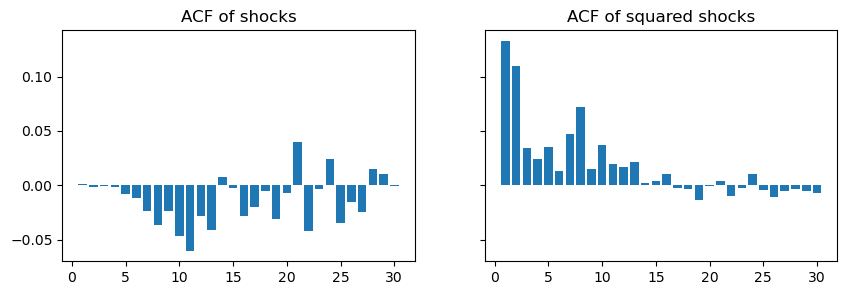

      sd_pct  sd_eur  mean_price
2019    18.7    11.2        50.4
2020    18.3     9.9        39.5
2021    15.0    20.5       111.4
2022    18.5    45.8       265.3
2023    28.4    19.2       103.7
2024    23.3    24.1       103.5
2025    16.2    17.0       108.2
2026    18.1    22.6       137.4


In [3]:
print('Ljung-Box Q(10): shocks %.1f, squared shocks %.1f (critical 18.31)' % (acorr_ljungbox(E_PCT, [10])['lb_stat'].iloc[0],
      acorr_ljungbox(E_PCT ** 2, [10])['lb_stat'].iloc[0]))
print('ARCH-LM(10): %.1f, p = %.2g' % het_arch(E_PCT, nlags=10)[:2])
z = (E_PCT - E_PCT.mean()) / E_PCT.std()
print('excess kurtosis %.1f, skewness %.2f, |z|>4: %d (normal: %.2f)' % (E_PCT.kurt(), E_PCT.skew(), (z.abs() > 4).sum(), len(z) * 2 * stats.norm.sf(4)))
fig, ax = plt.subplots(1, 2, figsize=(10, 3), sharey=True)
ax[0].bar(range(1, 31), acf(E_PCT, nlags=30)[1:]); ax[0].set_title('ACF of shocks')
ax[1].bar(range(1, 31), acf(E_PCT ** 2, nlags=30)[1:]); ax[1].set_title('ACF of squared shocks'); plt.show()
by = pd.DataFrame({'sd_pct': E_PCT.groupby(E_PCT.index.year).std(), 'sd_eur': E_EUR.groupby(E_EUR.index.year).std(),
                   'mean_price': PR['RO'].groupby(PR['RO'].index.year).mean()})
print(by.round(1))

In [4]:
def mkt_returns(px, drop_roll=False, vol=None):
    px = px.dropna()
    if vol is not None:
        px = px[vol.reindex(px.index).fillna(0) > 0]
    r = 100 * np.log(px).diff().dropna()
    n_roll = 0
    if drop_roll:   # first trading day of each month: front-month contract changes (cross-contract jump, not a price move)
        first = r.index.to_series().groupby(r.index.to_period("M")).transform("min") == r.index
        n_roll = int(first.sum())
        r = r[~first]
    return r, n_roll


BRENT, n_roll = mkt_returns(FU['brent_usd_bbl'].loc[str(START - pd.Timedelta(days=10)):str(END)], drop_roll=True); BRENT = BRENT.loc[START:END]
EUAR, _ = mkt_returns(EUA.loc[:str(END)])
SNP, _ = mkt_returns(EQ['SNP_adjclose_ron'].loc[str(START - pd.Timedelta(days=10)):str(END)], vol=EQ['SNP_volume']); SNP = SNP.loc[START:END]
print('Brent roll days dropped:', n_roll)
ann = pd.DataFrame({'RO power': E_PCT.groupby(E_PCT.index.year).std() * np.sqrt(365),
                    'EUA': EUAR.groupby(EUAR.index.year).std() * np.sqrt(252), 'Brent': BRENT.groupby(BRENT.index.year).std() * np.sqrt(252),
                    'OMV Petrom': SNP.groupby(SNP.index.year).std() * np.sqrt(252)})
print('annualised volatility, %'); print(ann.round(0))

Brent roll days dropped: 95
annualised volatility, %
      RO power   EUA  Brent  OMV Petrom
2019     358.0   NaN   30.0        24.0
2020     349.0   NaN   71.0        35.0
2021     287.0  63.0   32.0        22.0
2022     354.0  53.0   46.0        22.0
2023     543.0  32.0   31.0        18.0
2024     444.0  37.0   25.0        17.0
2025     310.0  24.0   29.0        20.0
2026     346.0  28.0   56.0        21.0


## §3 GARCH(1,1) cu șocuri de tip Student; persistența și timpul de înjumătățire

percent normal loglik -12360.3 BIC 24744.5 alpha+beta 0.927 half-life 9.2 days
percent t loglik -12094.5 BIC 24220.8 alpha+beta 0.746 half-life 2.4 days


EUR/MWh normal loglik -12274.7 BIC 24573.2 alpha+beta 0.998 half-life 283.0 days


EUR/MWh t loglik -12209.4 BIC 24450.7 alpha+beta 0.994 half-life 113.5 days
                          Zero Mean - GARCH Model Results                           
Dep. Variable:                            y   R-squared:                       0.000
Mean Model:                       Zero Mean   Adj. R-squared:                  0.000
Vol Model:                            GARCH   Log-Likelihood:               -12209.4
Distribution:      Standardized Student's t   AIC:                           24426.8
Method:                  Maximum Likelihood   BIC:                           24450.7
                                              No. Observations:                 2853
Date:                      Fri, Nov 06 2026   Df Residuals:                     2853
Time:                              23:24:19   Df Model:                            0
                             Volatility Model                             
                 coef    std err          t      P>|t|    95.0% Conf. Int.
---------

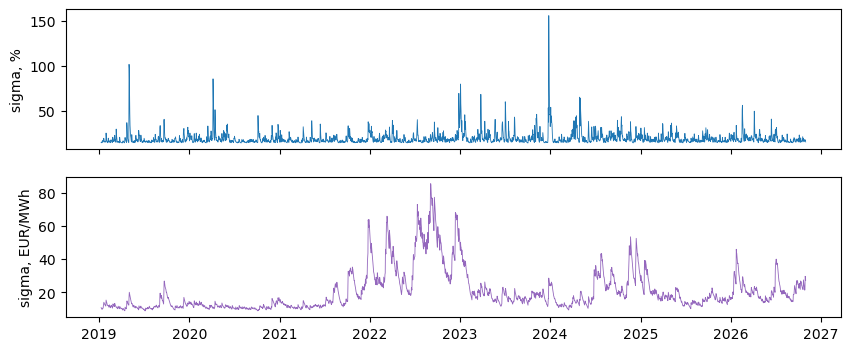

In [5]:
def fit(e, vol="GARCH", o=0, dist="t"):
    return arch_model(np.asarray(e, float), mean="Zero", vol=vol, p=1, o=o, q=1, dist=dist, rescale=False).fit(disp="off", show_warning=False)


def persistence(res, vol="GARCH", o=0):
    p = res.params
    if vol == "EGARCH":
        return float(p["beta[1]"])
    return float(p["alpha[1]"] + p["beta[1]"] + (0.5 * p["gamma[1]"] if o else 0))


def half_life(ph):
    return np.log(0.5) / np.log(ph) if 0 < ph < 1 else None


for unit, e in [('percent', E_PCT), ('EUR/MWh', E_EUR)]:
    for dist in ['normal', 't']:
        r = fit(e, dist=dist); ph = persistence(r)
        print(unit, dist, 'loglik %.1f BIC %.1f alpha+beta %.3f half-life %.1f days' % (r.loglikelihood, r.bic, ph, half_life(ph) or np.inf))
g_pct, g_eur = fit(E_PCT), fit(E_EUR)
print(g_eur.summary())
fig, ax = plt.subplots(2, 1, figsize=(10, 4), sharex=True)
ax[0].plot(E_PCT.index, g_pct.conditional_volatility, lw=0.6); ax[0].set_ylabel('sigma, %')
ax[1].plot(E_EUR.index, g_eur.conditional_volatility, lw=0.6, color='C4'); ax[1].set_ylabel('sigma, EUR/MWh'); plt.show()

(alpha+beta, half-life in days): {'RO %': (0.746, np.float64(2.4)), 'RO EUR/MWh': (0.994, np.float64(113.5)), 'Brent': (0.973, np.float64(25.6)), 'EUA': (0.992, np.float64(82.8)), 'OMV Petrom': (0.934, np.float64(10.2))}


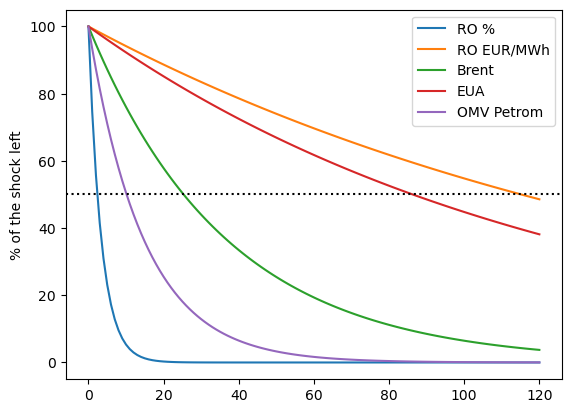

In [6]:
hl = {}
for k, e in [('RO %', E_PCT), ('RO EUR/MWh', E_EUR), ('Brent', BRENT - BRENT.mean()), ('EUA', EUAR - EUAR.mean()), ('OMV Petrom', SNP - SNP.mean())]:
    ph = persistence(fit(e.dropna())); hl[k] = (round(ph, 3), round(half_life(ph), 1))
print('(alpha+beta, half-life in days):', hl)
h = np.arange(121)
for k, (ph, _) in hl.items():
    plt.plot(h, 100 * ph ** h, label=k)
plt.axhline(50, ls=':', c='k'); plt.ylabel('% of the shock left'); plt.legend(); plt.show()

## §4 Asimetria: GJR și EGARCH, curba de impact a șocurilor, volatilitatea și nivelul prețului

percent GJR gamma 0.224 (t 2.9) | EGARCH gamma -0.083 (t -3.9) | BIC: GJR 24214.1, EGARCH 24219.2
EUR/MWh GJR gamma -0.127 (t -6.4) | EGARCH gamma 0.104 (t 7.2) | BIC: GJR 24411.7, EGARCH 24403.9


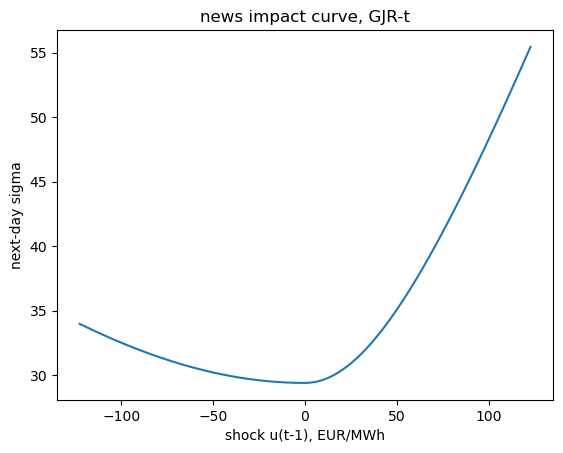

log monthly sd(u) on log mean price: slope 0.75, R2 0.76


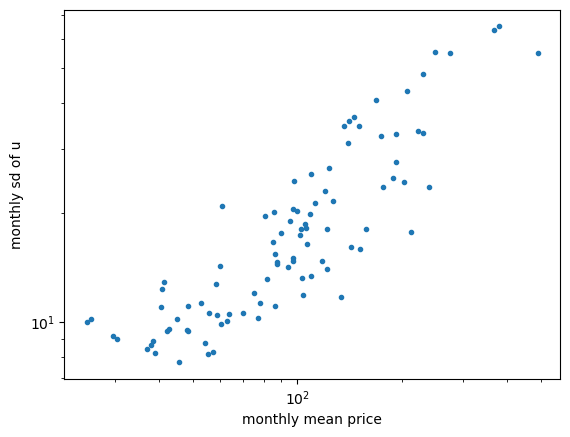

In [7]:
for unit, e in [('percent', E_PCT), ('EUR/MWh', E_EUR)]:
    gj, eg = fit(e, o=1), fit(e, vol='EGARCH', o=1)
    print(unit, 'GJR gamma %.3f (t %.1f) | EGARCH gamma %.3f (t %.1f) | BIC: GJR %.1f, EGARCH %.1f' % (
          gj.params['gamma[1]'], gj.tvalues['gamma[1]'], eg.params['gamma[1]'], eg.tvalues['gamma[1]'], gj.bic, eg.bic))
p = fit(E_EUR, o=1).params; ph = p['alpha[1]'] + p['gamma[1]'] / 2 + p['beta[1]']; s2 = p['omega'] / (1 - ph)
x = np.linspace(-4, 4, 201) * np.sqrt(s2)
plt.plot(x, np.sqrt(p['omega'] + p['beta[1]'] * s2 + (p['alpha[1]'] + p['gamma[1]'] * (x < 0)) * x ** 2))
plt.xlabel('shock u(t-1), EUR/MWh'); plt.ylabel('next-day sigma'); plt.title('news impact curve, GJR-t'); plt.show()
m = pd.DataFrame({'sd': E_EUR.groupby(E_EUR.index.to_period('M')).std(), 'lvl': PR['RO'].groupby(PR['RO'].index.to_period('M')).mean()}).dropna()
ll = sm.OLS(np.log(m['sd']), sm.add_constant(np.log(m['lvl']))).fit()
print('log monthly sd(u) on log mean price: slope %.2f, R2 %.2f' % (ll.params.iloc[1], ll.rsquared))
plt.loglog(m['lvl'], m['sd'], 'o', ms=3); plt.xlabel('monthly mean price'); plt.ylabel('monthly sd of u'); plt.show()

## §5 Regimuri: modelul Markov și persistența pe perioade

sd calm / turbulent: 12.9 / 41.9 EUR/MWh; expected durations: [69.1 23. ]
share of turbulent days by year, %: {2019: 1.0, 2020: 0.0, 2021: 20.0, 2022: 86.0, 2023: 15.0, 2024: 32.0, 2025: 6.0, 2026: 33.0}


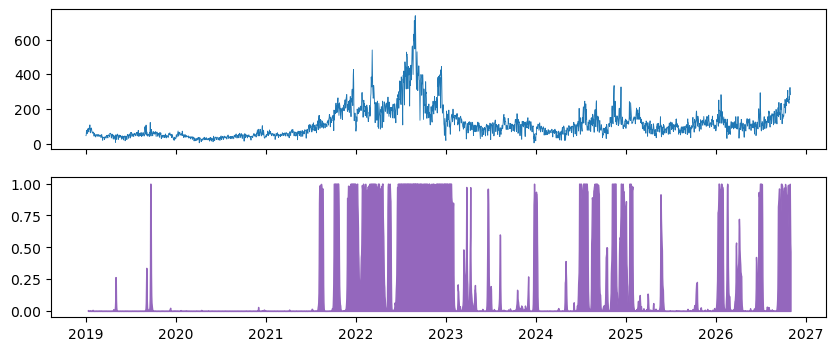

2019 - 2020 alpha+beta: 0.568 (%), 0.209 (EUR/MWh)
2021 - 2022 alpha+beta: 0.882 (%), 1.000 (EUR/MWh)
2023 - 2026 alpha+beta: 0.727 (%), 0.927 (EUR/MWh)


In [8]:
np.random.seed(20261106)
ms = MarkovRegression(E_EUR.values, k_regimes=2, trend='c', switching_variance=True).fit(search_reps=20, disp=False)
hi = int(np.argmax(ms.params[-2:])); P_ = ms.regime_transition[:, :, 0]
print('sd calm / turbulent: %.1f / %.1f EUR/MWh; expected durations:' % tuple(np.sqrt(np.sort(ms.params[-2:]))), np.round(ms.expected_durations, 1))
prob = pd.Series(ms.smoothed_marginal_probabilities[:, hi], index=E_EUR.index)
print('share of turbulent days by year, %:', (100 * (prob > 0.5).groupby(prob.index.year).mean()).round(0).to_dict())
fig, ax = plt.subplots(2, 1, figsize=(10, 4), sharex=True); ax[0].plot(PR['RO'], lw=0.6); ax[1].fill_between(prob.index, 0, prob, color='C4'); plt.show()
for a, b in [('2019-01-01', '2020-12-31'), ('2021-01-01', '2022-12-31'), ('2023-01-01', str(END.date()))]:
    print(a[:4], '-', b[:4], 'alpha+beta: %.3f (%%), %.3f (EUR/MWh)' % (persistence(fit(E_PCT.loc[a:b])), persistence(fit(E_EUR.loc[a:b]))))

## §6 Variația intrazilnică din prețurile orare; producția solară; modelul HAR

      mean RV  median RV/price  solar MW
2019    35.51             0.64    156.64
2020    25.27             0.60    152.78
2021    69.46             0.55    147.87
2022   186.17             0.65    155.98
2023   101.65             0.96    167.00
2024   152.00             1.24    237.61
2025   125.22             1.18    310.29
2026   134.71             1.01    592.98
const    0.079
d        0.398
w        0.365
m        0.218
dtype: float64 R2 0.82
test-year MAE: HAR 35.6, yesterday 39.1 EUR/MWh


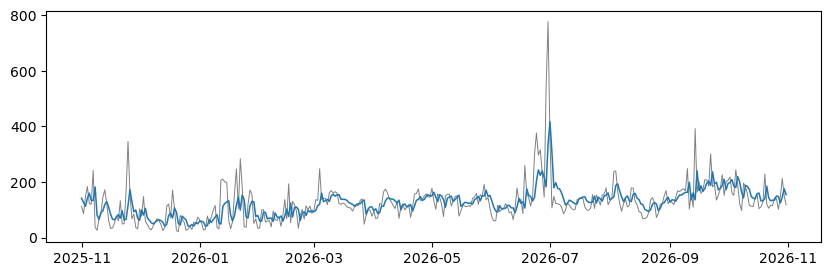

In [9]:
HP = pd.read_csv(DATA + 'power_da_prices_hourly_utc.csv', parse_dates=['timestamp_utc']).set_index('timestamp_utc')['RO'].dropna()
HP.index = HP.index.tz_convert(TZ); HP = HP.loc[str(START.date()):str(END.date())]
h = pd.DataFrame({'p': HP.values, 'day': HP.index.tz_localize(None).normalize()}); h['dp'] = h.groupby('day')['p'].diff()
g = h.groupby('day')
RV = pd.DataFrame({'rv': np.sqrt(g['dp'].apply(lambda x: (x ** 2).sum(min_count=1))), 'lvl': g['p'].mean()}).reindex(CAL)
RV['rel'] = RV['rv'] / RV['lvl'].abs()
print(pd.DataFrame({'mean RV': RV['rv'].groupby(RV.index.year).mean(), 'median RV/price': RV['rel'].groupby(RV.index.year).median(),
                    'solar MW': GEN['solar'].reindex(CAL).groupby(CAL.year).mean()}).round(2))


def har_design(rv):
    lr = np.log(rv)
    return pd.DataFrame({"y": lr, "d": lr.shift(1), "w": lr.shift(1).rolling(7).mean(), "m": lr.shift(1).rolling(30).mean()})


TEST0 = END - pd.Timedelta(days=364); TDAYS = pd.date_range(TEST0, END)
HD = har_design(RV['rv']).dropna(); tr = HD.loc[:TEST0 - pd.Timedelta(days=1)]
har = sm.OLS(tr['y'], sm.add_constant(tr[['d', 'w', 'm']])).fit(cov_type='HAC', cov_kwds={'maxlags': 7}); print(har.params.round(3), 'R2 %.2f' % har.rsquared)
pred = []
for t in TDAYS:
    tr = HD.loc[:t - pd.Timedelta(days=1)]; X = sm.add_constant(tr[['d', 'w', 'm']]).values
    b = np.linalg.lstsq(X, tr['y'].values, rcond=None)[0]; s2 = np.var(tr['y'].values - X @ b)
    pred.append(np.exp(np.r_[1.0, HD.loc[t, ['d', 'w', 'm']].values] @ b + 0.5 * s2))
HARF = pd.Series(pred, index=TDAYS); act = RV['rv'].loc[TDAYS]
print('test-year MAE: HAR %.1f, yesterday %.1f EUR/MWh' % ((HARF - act).abs().mean(), (RV['rv'].shift(1).loc[TDAYS] - act).abs().mean()))
plt.figure(figsize=(10, 3)); plt.plot(act, c='grey', lw=0.7); plt.plot(HARF, lw=1.1); plt.show()

## §7 Prognoza și evaluarea volatilității: prognoze glisante, QLIKE, testul DM, prognoze pe mai mulți pași
Fiecare model este reestimat în fiecare zi a anului de test, pe datele pînă în ziua precedentă (inclusiv ecuația mediei).

pct {'hist30': np.float64(1.523), 'ewma': np.float64(1.499), 'garch': np.float64(1.459), 'gjr': np.float64(1.445), 'egarch': np.float64(1.452)}
   p (beats 30-day history): {'ewma': np.float64(0.082), 'garch': np.float64(0.17), 'gjr': np.float64(0.145), 'egarch': np.float64(0.12)}


eur {'hist30': np.float64(1.428), 'ewma': np.float64(1.398), 'garch': np.float64(1.378), 'gjr': np.float64(1.357), 'egarch': np.float64(1.349)}
   p (beats 30-day history): {'ewma': np.float64(0.026), 'garch': np.float64(0.04), 'gjr': np.float64(0.032), 'egarch': np.float64(0.027)}


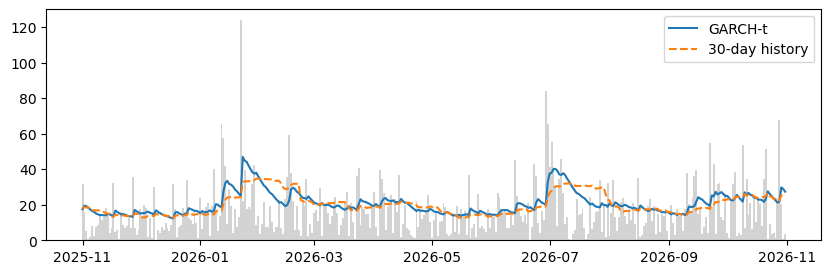

In [10]:
def one_day(y, t):
    """All volatility forecasts for day t from data up to t-1 (mean equation re-estimated on the same window)."""
    X = mean_design(y)
    df = pd.concat([y.rename("y"), X], axis=1)
    tr = df.loc[:t - pd.Timedelta(days=1)].dropna()
    Xt, yt = tr.drop(columns="y").values, tr["y"].values
    b = np.linalg.lstsq(Xt, yt, rcond=None)[0]
    e_tr = yt - Xt @ b
    yhat = float(df.loc[t].drop("y").values @ b)
    out = {"y": float(df.loc[t, "y"]), "yhat": yhat, "e": float(df.loc[t, "y"]) - yhat}
    out["hist30"] = float(np.mean(e_tr[-30:] ** 2))
    s2 = float(np.var(e_tr[:30]))
    for x in e_tr:                                   # RiskMetrics exponentially weighted moving average, lambda = 0.94
        s2 = 0.94 * s2 + 0.06 * x ** 2
    out["ewma"] = s2
    for nm, vol, o in [("garch", "GARCH", 0), ("gjr", "GARCH", 1), ("egarch", "EGARCH", 1)]:
        res = fit(e_tr, vol, o)
        out[nm] = float(res.forecast(horizon=1, reindex=False).variance.values[-1, 0])
        if nm == "garch":
            out["nu"] = float(res.params["nu"])
    return out


def qlike(proxy, h):
    x = proxy / h
    return x - np.log(x) - 1


def nw_var(x, lags=7):
    x = x - x.mean()
    n = len(x)
    v = x @ x / n
    for k in range(1, lags + 1):
        v += 2 * (1 - k / (lags + 1)) * (x[k:] @ x[:-k]) / n
    return v


def dm(la, lb, lags=7):
    """One-sided DM test: H1 = model b has lower expected loss than model a."""
    dl = np.asarray(la) - np.asarray(lb)
    st = dl.mean() / np.sqrt(nw_var(dl, lags) / len(dl))
    return st, 1 - stats.norm.cdf(st)


VMODELS = ['hist30', 'ewma', 'garch', 'gjr', 'egarch']
ROLL = {}
for u, y in [('pct', R_PCT['RO']), ('eur', R_EUR['RO'])]:
    R = pd.DataFrame(Parallel(n_jobs=-1)(delayed(one_day)(y.loc[START:END], t) for t in TDAYS), index=TDAYS); ROLL[u] = R
    px = R['e'] ** 2; L = {k: qlike(px, R[k]) for k in VMODELS}
    print(u, {k: round(L[k].mean(), 3) for k in VMODELS})
    print('   p (beats 30-day history):', {k: round(dm(L['hist30'], L[k])[1], 3) for k in VMODELS[1:]})
R = ROLL['eur']; plt.figure(figsize=(10, 3)); plt.bar(R.index, R['e'].abs(), color='lightgrey', width=1)
plt.plot(np.sqrt(R['garch']), label='GARCH-t'); plt.plot(np.sqrt(R['hist30']), '--', label='30-day history'); plt.legend(); plt.show()

Brent on 2026-04-09 : 20-day 90% band GARCH +/-38.5%, sigma*sqrt(20) +/-43.1%


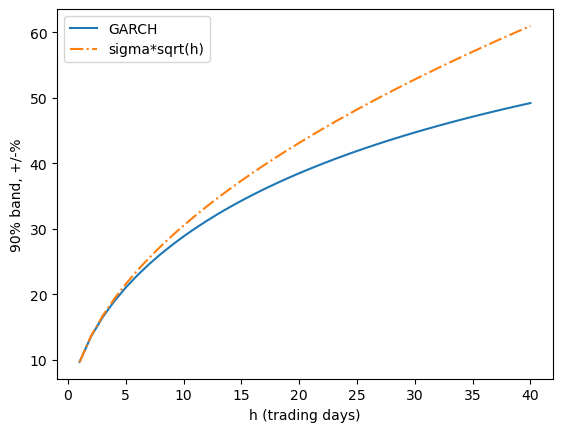

In [11]:
gb = fit(BRENT - BRENT.mean()); cvb = pd.Series(gb.conditional_volatility, index=BRENT.index) * np.sqrt(252)
peak = cvb.loc[str(END.year)].idxmax(); xb = BRENT.loc[:peak]; gp = fit(xb - xb.mean())
f = gp.forecast(horizon=40, reindex=False).variance.values[-1]; z95 = stats.norm.ppf(0.95)
print('Brent on', peak.date(), ': 20-day 90%% band GARCH +/-%.1f%%, sigma*sqrt(20) +/-%.1f%%' % (z95 * np.sqrt(f[:20].sum()), z95 * np.sqrt(20 * f[0])))
hh = np.arange(1, 41); plt.plot(hh, z95 * np.sqrt(np.cumsum(f)), label='GARCH'); plt.plot(hh, z95 * np.sqrt(hh * f[0]), '-.', label='sigma*sqrt(h)')
plt.xlabel('h (trading days)'); plt.ylabel('90% band, +/-%'); plt.legend(); plt.show()

## §8 Studiu de caz: prețul energiei electrice din România în 2026
Banda de 90% pentru ziua următoare, calculată cu GARCH-t în anul de test, și prognoza la sfîrșitul perioadei. Studiul de caz C3 (acțiuni energetice și petrol, DCC-GARCH) are propriul notebook Jupyter în `../cases/C3_energy_stocks/`.

days outside the 90% band: 38 of 365 (10.4%)


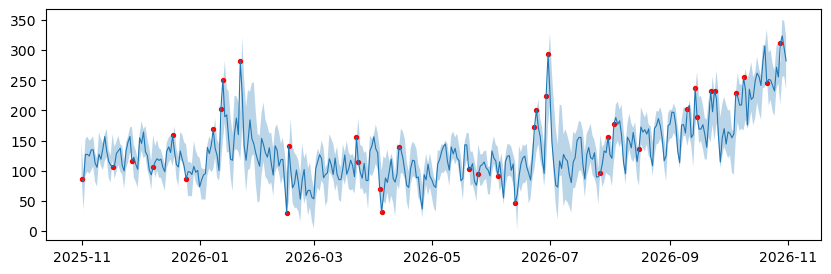

sigma for the next day 26.0 EUR/MWh, long-run 27.6; one-day 90% limit +/-43 EUR/MWh


In [12]:
R = ROLL['eur']; q = stats.t.ppf(0.95, R['nu']) * np.sqrt((R['nu'] - 2) / R['nu']); w = q * np.sqrt(R['garch'])
out = R['e'].abs() > w
print('days outside the 90%% band: %d of %d (%.1f%%)' % (out.sum(), len(out), 100 * out.mean()))
center = PR['RO'].shift(1).loc[TDAYS] + R['yhat']
plt.figure(figsize=(10, 3)); plt.fill_between(TDAYS, center - w, center + w, alpha=0.3); plt.plot(PR['RO'].loc[TDAYS], lw=0.8)
plt.scatter(out[out].index, PR['RO'].loc[out[out].index], c='r', s=8); plt.show()
f = g_eur.forecast(horizon=30, reindex=False).variance.values[-1]
p = g_eur.params; lr = p['omega'] / (1 - p['alpha[1]'] - p['beta[1]'])
print('sigma for the next day %.1f EUR/MWh, long-run %.1f; one-day 90%% limit +/-%.0f EUR/MWh' % (np.sqrt(f[0]), np.sqrt(lr), stats.norm.ppf(0.95) * np.sqrt(f[0])))